# Import libraries

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data

In [2]:
df = pd.read_csv("/Users/kelsie/Desktop/SeattleU/DATA5100/DATA5100-education/data/education_clean.csv")

In [3]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,teachers
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,25.0
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,87.0
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,95.0
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,98.0
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,134.0


# Modeling

## Single input models
Fit and assess models predicting the average ACT score from each of the input variables, starting with polynomial linear regression models, as appropriate.

### Median income

#### Plot the regression line and the scatter plot

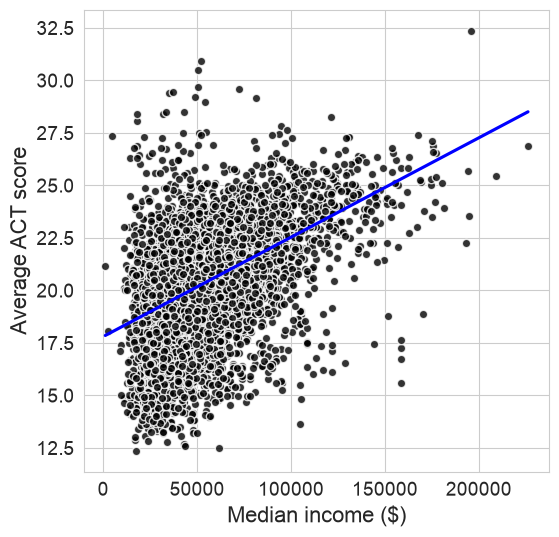

In [39]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

### Fit the simple linear regression model

In [64]:
model_median_income = smf.ols(formula = 'average_act ~ median_income', data = df).fit()

#### Display the fit summary: check the sign and significance of the coefficients

In [65]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:32:05   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

#### Numerical assessment of fit accuracy

##### Compute the the R-squared
R-squared indicates how many the variation in the response variable is explained by the model.

In [66]:
model_median_income.rsquared

np.float64(0.211186489774996)

##### Compute the RMSE
RMSE measures prediction errors, but penalizes larger errors more heavily.

In [67]:
y_hat = model_median_income.predict()

In [68]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(2.228)

##### Compute the mean absolute error (MAE)
MAE measures the average absolute difference between predicted and actual values.

In [69]:
mean_absolute_error(df['average_act'], y_hat)

1.7129386981153911

A higher R-squared generally indicates a better fit, while lower RMSE and MAE indicate smaller prediction errors.

#### Use a residual plot for graphical assessment of model fit
Residual the error between the actual value and the predicted value.

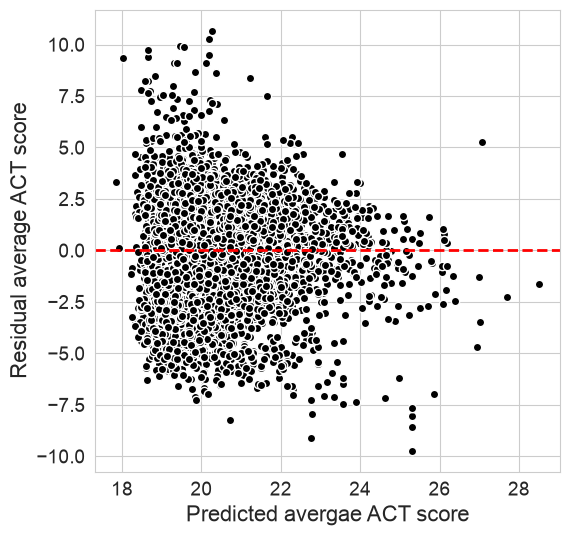

In [70]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_median_income.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted avergae ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The residuals are scattered around zero, but their spread is not constant across predicted values. There are also some outliers. This suggests possible heteroscedasticity (non constant variance), and indicates that the linear regression model may not fully capture the patterns in the data.

#### Attempt at a quadratic model. Plot the regression curves and the scatter plot

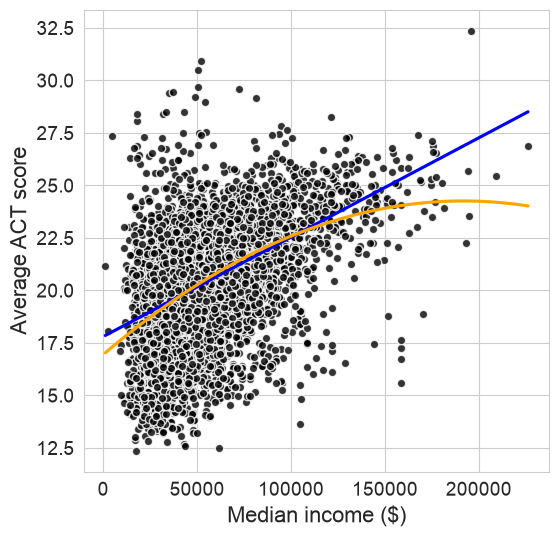

In [71]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           order = 2, # compute a quadratic regression line
           color = 'orange',
           ci = False,
           scatter = False)

# Add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

### Fit a quadratic linear regression model

In [48]:
model_median_income2 = smf.ols(
    formula = 'average_act ~ median_income + I(median_income**2)', # I is an indicator for the second term
    data = df).fit()

#### Display the fit summary

In [49]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:31:12   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

#### Assess the model significance

In [50]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

We can see the signifiance of the linear term and quadratic term.

#### Compare two nested polynomial linear regression models: simpler model vs more complicated model

In [51]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012795,0.0,NaN,NaN,NaN
1,7224.0,35505.105961,1.0,359.906834,73.227974,1.395848e-17


P-value indicated there's a statistically significant difference between these two models.

#### Assess the model accuracy

Compute the mean absolute error

In [52]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.697238925796724

In [53]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.7129386981153911

Both models provide some predictive power of what the ACT score actually is. But they are relatively weak predictions. And we've also seen that a linear model is probably going to be sufficient to predict the ACT score, and that considering the quadratic is not necessarily going to provide a much better fit. It might be possible to consider a different nonlinear transformation of the median income. 

I will leave the further analysis of possible additional nonlinear transformations and also further analyses of single input models using the other predictors to you, and then we will consider a multiple linear regression model that combines the predictors.

### Number of Teachers

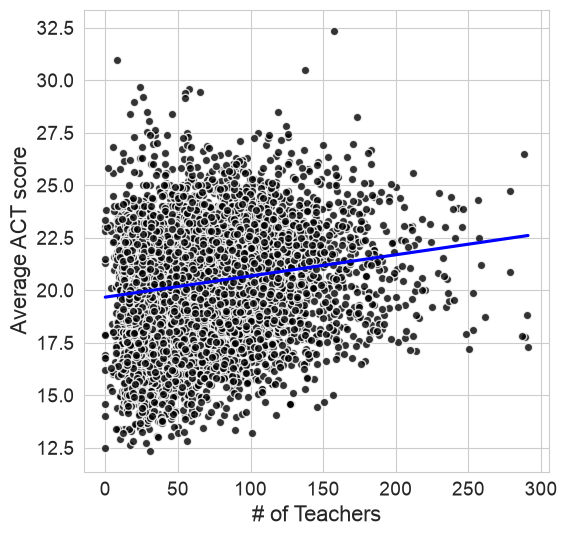

In [98]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'teachers',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('# of Teachers', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

### Fit the simple linear regression model

In [74]:
model_teachers = smf.ols(formula = 'average_act ~ teachers', data = df).fit()

#### Display the fit summary: check the sign and significance of the coefficients

In [75]:
print(model_teachers.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.030
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     225.9
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           2.62e-50
Time:                        15:35:00   Log-Likelihood:                -16789.
No. Observations:                7227   AIC:                         3.358e+04
Df Residuals:                    7225   BIC:                         3.360e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     19.6709      0.051    386.659      0.0

In [77]:
model_teachers.rsquared

np.float64(0.030324431725555323)

The low R-squared indicates this is a poor fit.

## Multiple linear regression
Fit multiple linear regression model using all socioeconomic variables as predictors. Your can also include other transformation for the current variables or include more variables in your model.

In [78]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + teachers',
    data = df).fit()

### Print the summary

In [79]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.631
Method:                 Least Squares   F-statistic:                     2062.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:49:24   Log-Likelihood:                -13293.
No. Observations:                7227   AIC:                         2.660e+04
Df Residuals:                    7220   BIC:                         2.665e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6030      0.13

### Use a residual plot for graphical assessment of model fit

In [80]:
y_hat = model.predict()

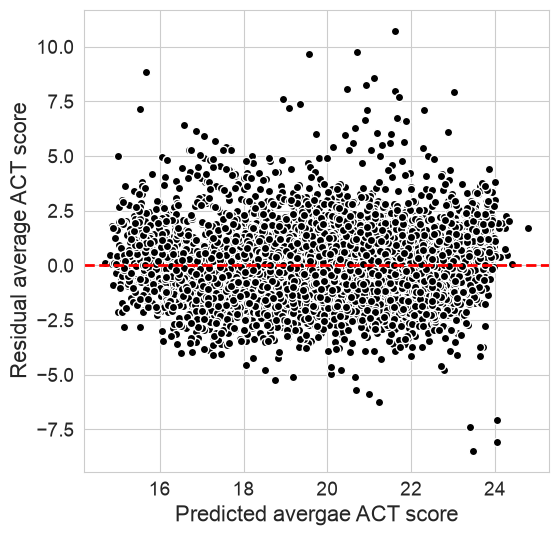

In [81]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted avergae ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

There's relatively no structure in the plot. We may not need any transformations for the input variables in the model.

### Compute the mean absolute error

In [82]:
mean_absolute_error(df['average_act'], model.predict())

1.1359433257025384

### Summary
1. The multiple linear regression model with all socioeconomic predictors can predict ACT scores with an average error of roughly 1 point using these predictors.
2. The residual plot suggests that there will be limited improvement from adding transformations of these predictors.
3. Not all predictors have significant coefficients.
4. Adding predictors to the model may improve the performance.

## Fit a reduced model with the significance predictors

In [83]:
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data = df).fit()

### Print the summary

In [84]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:49:55   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

All three variables have statistically significant coefficients.

### Use a residual plot for graphical assessment of model fit.

In [85]:
y_hat = model_reduced.predict()

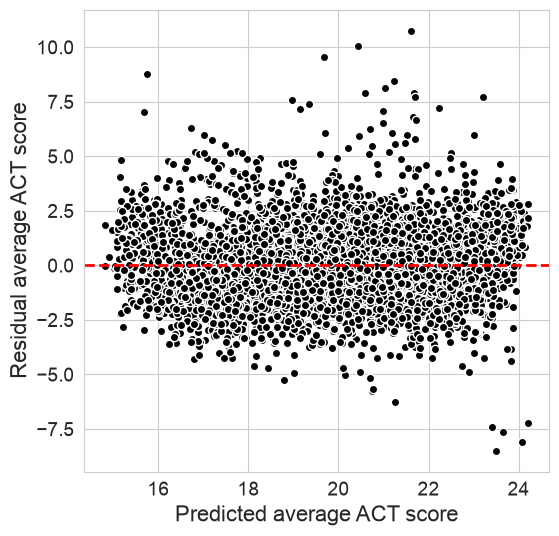

In [86]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_reduced.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

### Compute the mean absolute error

In [87]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.145483295066503

### Compare the accurary between full and reduced models

In [88]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
             'R-squared': [r2_full, r2_reduced]},
            index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1359,0.6315
reduced model,1.1455,0.6279


### Use an ANOVA to test the significance of difference between models

In [89]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619168,0.0,NaN,NaN,NaN
1,7220.0,16753.936188,3.0,162.68298,23.369058,4.771895e-15


### Summary
1. The model predicting average ACT score from rate_unemployment, percent_college, percent_lunch, and teachers is not significantly different than the model with all five socioeconomic variables as predictors.
2. Adding predictors to the model may improve the performance.
3. We have not yet determined the relative importance of each predictor in the model.

## Scaling

### Scale the predictor variables in the reduced model to have mean 0 and standard deviation 1 and add them to the data frame

In [90]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [91]:
# create a list of names of these scaled columns
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


In [92]:
# standardize/normalize
scaler = StandardScaler().fit(df[predictor_variables])

In [93]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

### Check the mean and standard deviation of the transformed data.

In [94]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


### Fit the multiple linear regression model with the normalized predictors

In [95]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

### Print the summary

In [96]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:50:51   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

### Compare the accurary between full and reduced models

In [97]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
             'R-squared': [r2_normalized, r2_reduced]},
            index = ['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1455,0.6279
reduced model,1.1455,0.6279


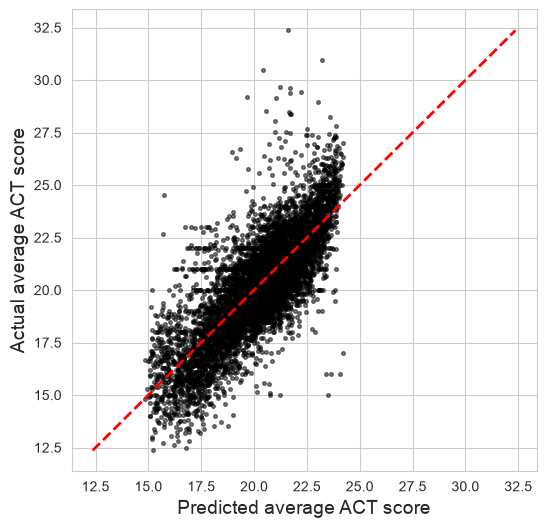

In [103]:
plt.figure(figsize = (6, 6))
plt.scatter(model_normalized.predict(), df['average_act'],
            s = 7, alpha = 0.5, color = 'k')
lims = [df['average_act'].min(), df['average_act'].max()]
plt.plot(lims, lims, 'r--', lw = 2)
plt.xlabel('Predicted average ACT score', fontsize = 14)
plt.ylabel('Actual average ACT score', fontsize = 14)
plt.show()

### Summary
1. The percent of students at a school receiving free or reduced price lunch was the strongest predictor in this analysis.

### Examine categorical variables

#### Charter school

In [102]:
df['charter'].value_counts()

charter
No                6858
Not applicable     199
Yes                170
Name: count, dtype: int64

In [100]:
model_charter = smf.ols(
    formula = 'average_act ~ percent_lunch_normalized + C(charter)',
    data = df).fit()
print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     3870.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:24:39   Log-Likelihood:                -13438.
No. Observations:                7227   AIC:                         2.688e+04
Df Residuals:                    7223   BIC:                         2.691e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [101]:
anova_lm(model_normalized, model_charter) 

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619168,0.0,NaN,NaN,NaN
1,7223.0,17438.597245,-0.0,-521.978078,inf,NaN


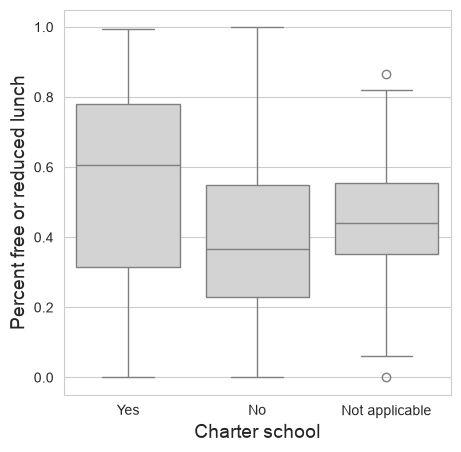

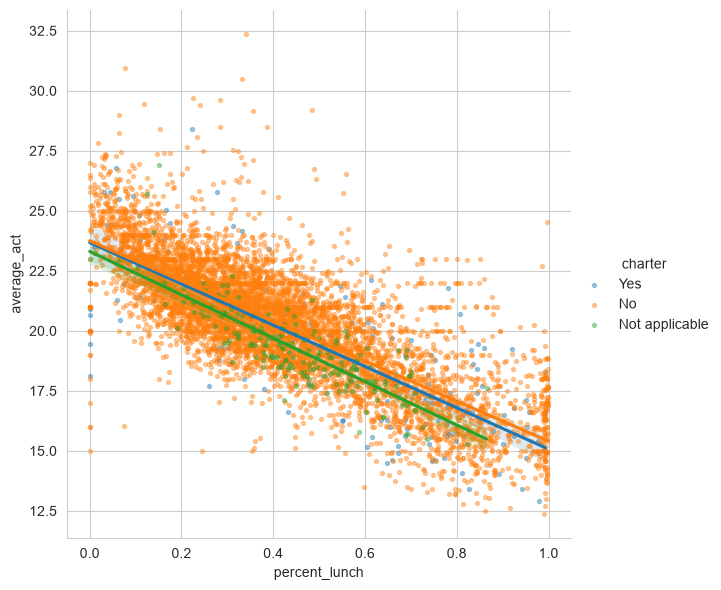

In [104]:
plt.figure(figsize = (5, 5))
sns.boxplot(data = df, x = 'charter', y = 'percent_lunch', color = 'lightgray')
plt.xlabel('Charter school', fontsize = 14)
plt.ylabel('Percent free or reduced lunch', fontsize = 14)
plt.show()

# Does the lunch/ACT relationship differ? Separate regression line per group
sns.lmplot(data = df, x = 'percent_lunch', y = 'average_act', hue = 'charter',
           height = 6, scatter_kws = {'alpha': 0.4, 's': 8})
plt.show()

#### Number of Teachers

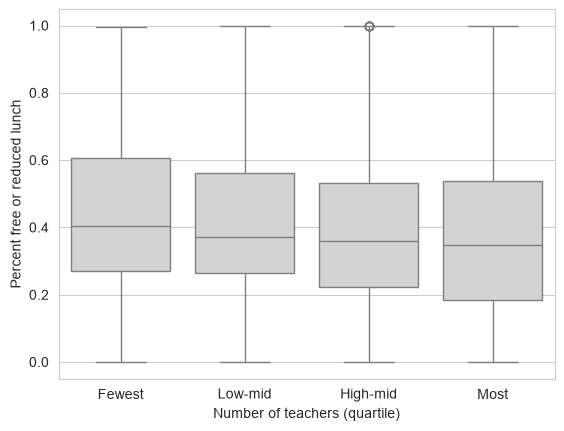

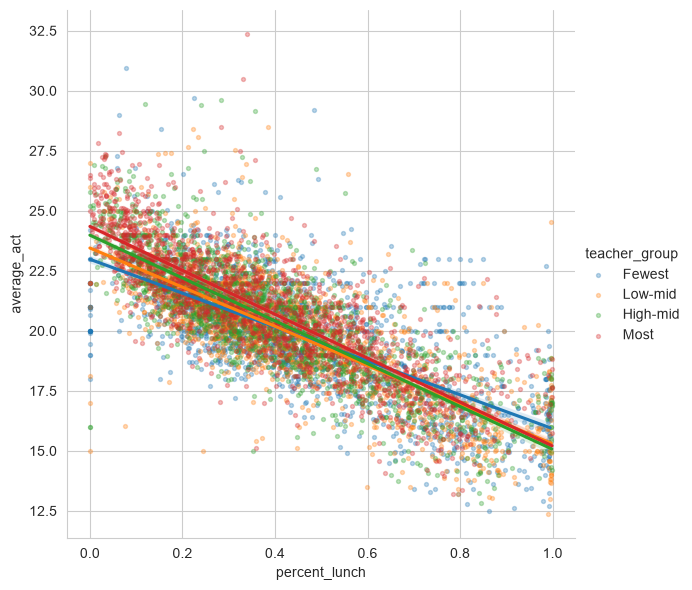

In [105]:
df['teacher_group'] = pd.qcut(df['teachers'], 4,
                              labels = ['Fewest', 'Low-mid', 'High-mid', 'Most'])

# Percent lunch by teacher-count quartile
sns.boxplot(data = df, x = 'teacher_group', y = 'percent_lunch', color = 'lightgray')
plt.xlabel('Number of teachers (quartile)')
plt.ylabel('Percent free or reduced lunch')
plt.show()

# ACT vs. lunch, colored by teacher-count quartile
sns.lmplot(data = df, x = 'percent_lunch', y = 'average_act', hue = 'teacher_group',
           height = 6, scatter_kws = {'alpha': 0.3, 's': 8})
plt.show()